In [7]:
!pip install qiskit qiskit-machine-learning qiskit-aer
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.quantum_info import SparsePauliOp

from qiskit.primitives import StatevectorEstimator
import matplotlib.pyplot as plt
from sklearn.datasets import make_circles, make_moons

import numpy as np
import pandas as pd

# Dataset

In [65]:
def scale_isotropic(X, target_range = (-np.pi, np.pi)):
  lo, hi = target_range
  X_centered = X - X.mean(axis=0)
  max_abs = np.abs(X_centered).max()
  scale = (hi - lo) / 2 / max_abs
  return X_centered * scale

### EDA
Sprawdzamy czy dane są zbalansowane klasami i czy nie zawierają żadnych pokrywających się rekordów

In [93]:
X, y = make_moons(n_samples = 400, noise = 0.1, random_state = 42)
df = pd.DataFrame(X, columns = ["x1", "x2"])
df["target"] = y

print(df.duplicated().sum())
print(f"Cały zbiór:   class 0 = {np.sum(y == 0)} | class 1 = {np.sum(y == 1)}")

X, y = make_circles(n_samples = 400, noise = 0.1, random_state = 42)
df = pd.DataFrame(X, columns = ["x1", "x2"])
df["target"] = y

print(df.duplicated().sum())
print(f"Cały zbiór:   class 0 = {np.sum(y == 0)} | class 1 = {np.sum(y == 1)}")

0
Cały zbiór:   class 0 = 200 | class 1 = 200
0
Cały zbiór:   class 0 = 200 | class 1 = 200


### Dobieranie odpowiedniego noise

In [45]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report

#### Dla make_moons

In [94]:
for noise in [0.1, 0.2, 0.3, 0.4, 0.45, 0.5, 0.6]:
  X, y = make_moons(n_samples = 400, noise = noise, random_state = 42)
  X_scaled = scale_isotropic(X, target_range=(-np.pi, np.pi))

  X_temp, X_test, y_temp, y_test = train_test_split(X_scaled, y, test_size = 0.2, random_state = 42, stratify = y)
  X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size = 0.25, random_state = 42, stratify = y_temp)

  kNN = KNeighborsClassifier(n_neighbors = 5).fit(X_train, y_train)
  y_pred = kNN.predict(X_test)
  print("----- noise = ", noise, "-----\n")
  print(classification_report(y_test, y_pred))

----- noise =  0.1 -----

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        40
           1       1.00      1.00      1.00        40

    accuracy                           1.00        80
   macro avg       1.00      1.00      1.00        80
weighted avg       1.00      1.00      1.00        80

----- noise =  0.2 -----

              precision    recall  f1-score   support

           0       0.92      0.90      0.91        40
           1       0.90      0.93      0.91        40

    accuracy                           0.91        80
   macro avg       0.91      0.91      0.91        80
weighted avg       0.91      0.91      0.91        80

----- noise =  0.3 -----

              precision    recall  f1-score   support

           0       0.83      0.88      0.85        40
           1       0.87      0.82      0.85        40

    accuracy                           0.85        80
   macro avg       0.85      0.85      0.85       

#### Dla make_circles

In [95]:
for noise in [0.1, 0.2, 0.3, 0.4, 0.45, 0.5, 0.6]:
  X, y = make_circles(n_samples = 400, noise = noise, factor = 0.5, random_state = 42)
  X_scaled = scale_isotropic(X, target_range=(-np.pi, np.pi))

  X_temp, X_test, y_temp, y_test = train_test_split(X_scaled, y, test_size = 0.2, random_state = 42, stratify = y)
  X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size = 0.25, random_state = 42, stratify = y_temp)

  kNN = KNeighborsClassifier(n_neighbors = 5).fit(X_train, y_train)
  y_pred = kNN.predict(X_test)
  print("----- noise = ", noise, "-----\n")
  print(classification_report(y_test, y_pred))

----- noise =  0.1 -----

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        40
           1       1.00      1.00      1.00        40

    accuracy                           1.00        80
   macro avg       1.00      1.00      1.00        80
weighted avg       1.00      1.00      1.00        80

----- noise =  0.2 -----

              precision    recall  f1-score   support

           0       0.80      0.90      0.85        40
           1       0.89      0.78      0.83        40

    accuracy                           0.84        80
   macro avg       0.84      0.84      0.84        80
weighted avg       0.84      0.84      0.84        80

----- noise =  0.3 -----

              precision    recall  f1-score   support

           0       0.70      0.88      0.78        40
           1       0.83      0.62      0.71        40

    accuracy                           0.75        80
   macro avg       0.77      0.75      0.75       

### Final Datasets

In [98]:
X_circles, y_circles = make_circles(n_samples = 400, noise = 0.3, factor = 0.5, random_state = 42)
X_moons, y_moons = make_moons(n_samples = 400, noise = 0.4, random_state = 42)

X_scaled_circles = scale_isotropic(X_circles, target_range=(-np.pi, np.pi))
X_scaled_moons = scale_isotropic(X_moons, target_range=(-np.pi, np.pi))

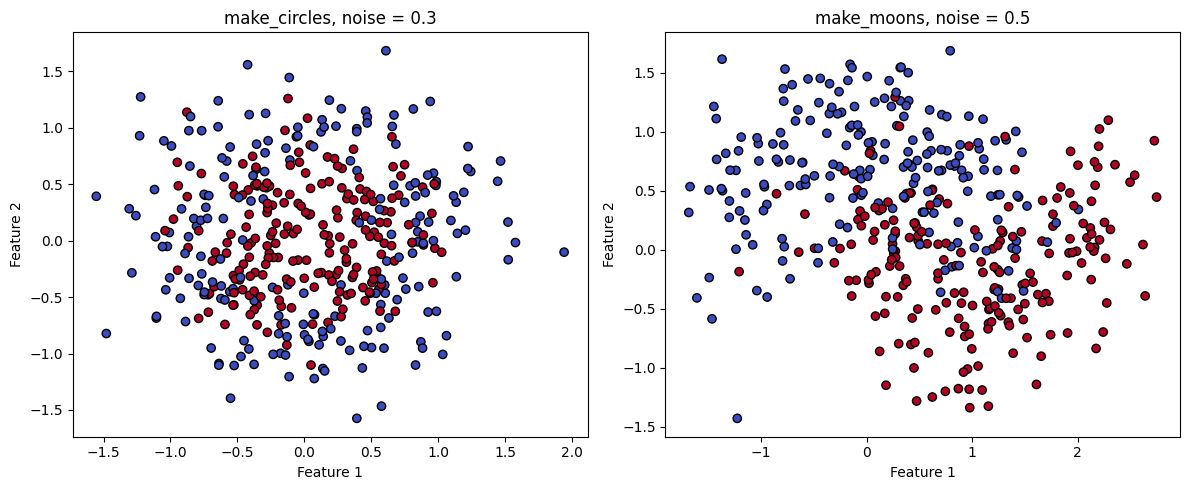

In [99]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Plot circles (noise=0.3)
axes[0].scatter(X_circles[:, 0], X_circles[:, 1], c=y_circles,
                cmap=plt.cm.coolwarm, edgecolors='k')
axes[0].set_title("make_circles, noise = 0.3")
axes[0].set_xlabel("Feature 1")
axes[0].set_ylabel("Feature 2")

# Plot moons (noise=0.5)
axes[1].scatter(X_moons[:, 0], X_moons[:, 1], c=y_moons,
                cmap=plt.cm.coolwarm, edgecolors='k')
axes[1].set_title("make_moons, noise = 0.5")
axes[1].set_xlabel("Feature 1")
axes[1].set_ylabel("Feature 2")

plt.tight_layout()
plt.show()

### Split danych

In [103]:
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(X_scaled_circles, y_circles, test_size = 0.2, random_state = 42, stratify = y_circles)
X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(X_scaled_moons, y_moons, test_size = 0.2, random_state = 42, stratify = y_moons)

y_train_c_signed = 2 * y_train_c - 1   # {0,1} -> {-1,1}
y_test_c_signed  = 2 * y_test_c  - 1
y_train_m_signed = 2 * y_train_m - 1
y_test_m_signed  = 2 * y_test_m  - 1

#### Tworzenie features i parametrów

In [104]:
x = ParameterVector("x", 2)  #features
th = ParameterVector("t", 4) #parameters θ

## Quantum Circuit

In [105]:
qc = QuantumCircuit(2) #Tworzenie obwodu

#Encoding
qc.ry(x[0], 0)
qc.ry(x[1], 1)

# Ansatz: rotacje - layer 1
qc.ry(th[0], 0)
qc.ry(th[1], 1)

#Entanglement
qc.cx(0, 1)

# Ansatz: rotacje - layer 2
qc.ry(th[2], 0)
qc.ry(th[3], 1)

Z0 = SparsePauliOp.from_sparse_list([("Z", [0], 1.0)], num_qubits=2)

print(qc)

     ┌──────────┐┌──────────┐     ┌──────────┐
q_0: ┤ Ry(x[0]) ├┤ Ry(t[0]) ├──■──┤ Ry(t[2]) ├
     ├──────────┤├──────────┤┌─┴─┐├──────────┤
q_1: ┤ Ry(x[1]) ├┤ Ry(t[1]) ├┤ X ├┤ Ry(t[3]) ├
     └──────────┘└──────────┘└───┘└──────────┘


### Querry in one batch

In [106]:
def batch(qc, Z0, X_batch, th_val, est):
  M = len(X_batch) # Ilosc probek w batchu
  P = len(th_val) # Liczba parametrow

  I = np.eye(P) # Maciez indentycznosci
  shift_plus = th_val + (np.pi/2)*I  # (P, P): dodawanie przeskalowanej macierzy identycznosci
  shift_minus = th_val - (np.pi/2)*I # (P, P): analogicznie
  shift_vectors = np.vstack([shift_plus, shift_minus]) # ustawiamy wertykalnie shape (2P, P)

  X_tiled = np.tile(X_batch, (2*P + 1, 1))  # ((2P+1)*M, n_features)

  theta_forward = np.tile(th_val, (M, 1)) #(M, P)
  theta_shifted = np.repeat(shift_vectors, M, axis=0) #(2P*M, P)
  theta_full = np.vstack([theta_forward, theta_shifted]) # ((2P+1)*M)
  # Dodajemy na początku nie zmienione parametry (Forward Pass)
  params = np.hstack([X_tiled, theta_full])

  res = est.run([(qc, Z0, params)]).result()[0]
  vals = res.data.evs.reshape(2*P+1, M) # rzad i = wyniki dla shift_vector[i] po wszystkich probkach (M)

  f, f_plus, f_minus = vals[0], vals[1:P+1], vals[P+1:] # f - forward pass (M, 1) f_plus, f_minus - macierz (P, M)
  dfdtheta = (f_plus - f_minus)/2
  return f, dfdtheta

## Training function for standard threshold

In [120]:
def train_qnn(qc, Z0, X_train, y_train, X_test, y_test, num_epochs = 50, batch_size = 32, lr = 0.1, seed = 0):
  rng = np.random.default_rng(seed)  # ustalenie stałego rng
  th = rng.uniform(-0.1, 0.1, 4)     # init theta
  est = StatevectorEstimator()       # estimator

  history = {"loss": [], "train_acc": [], "test_acc": [],
             "grad_norm": [], "grad_norm_full": [],
             "mean_abs_f_train": []}

  N = len(X_train)
  for epoch in range(num_epochs):
    perm = rng.permutation(N)
    X_shuf, y_shuf = X_train[perm], y_train[perm] # W każdej epoce permutujemy dane

    epoch_loss = 0.0
    epoch_grad_norm = 0.0
    n_batches = 0

    for start in range(0, N, batch_size):
      X_batch = X_shuf[start:start + batch_size]
      y_batch = y_shuf[start:start + batch_size]

      M = len(X_batch)
      if M == 0: continue

      f_batch, dfdtheta = batch(qc, Z0, X_batch, th, est)

      error = f_batch - y_batch
      grad_L = 2 * dfdtheta @ error / M
      th -= lr * grad_L

      epoch_loss += np.mean(error**2) * M        # Wartość straty
      epoch_grad_norm += np.linalg.norm(grad_L)   # Norma gradientu
      n_batches += 1                              # Liczba batchy

    history["loss"].append(epoch_loss / N)                     # Średnia wartość straty na próbkę w całej epoce
    history["grad_norm"].append(epoch_grad_norm / n_batches)   # Średnia norma gradientu na batch

    f_train, dfdtheta_full = batch(qc, Z0, X_train, th, est)   # Forward passy do liczenia accuracy
    f_test, _ = batch(qc, Z0, X_test, th, est)

    history["train_acc"].append(np.mean(np.sign(f_train) == y_train))
    history["test_acc"].append(np.mean(np.sign(f_test) == y_test))

    full_grad = 2 * dfdtheta_full @ (f_train - y_train) / len(X_train) # Gradient liczony na tych samych danych za każdym razem
    history["grad_norm_full"].append(np.linalg.norm(full_grad))

    history["mean_abs_f_train"].append(np.mean(np.abs(f_train)))

  return th, history

## Training function for classical overhead

In [146]:
def train_qnn_overhead(qc, Z0, X_train, y_train, X_test, y_test, num_epochs = 50, batch_size = 32, lr = 0.1, seed = 0):
  rng = np.random.default_rng(seed)  # ustalenie stałego rng
  th = rng.uniform(-0.1, 0.1, 4)     # init theta
  w = 1.0                            # inti: identity
  b = 0.0
  est = StatevectorEstimator()       # estimator

  history = {
      "loss": [], "train_acc": [], "test_acc": [],
      "grad_norm": [], "grad_norm_full": [],
      "mean_abs_f_train": [],
      "w": [], "b": []
      }

  N = len(X_train)
  for epoch in range(num_epochs):
    perm = rng.permutation(N)
    X_shuf, y_shuf = X_train[perm], y_train[perm] # W każdej epoce permutujemy dane

    epoch_loss = 0.0
    epoch_grad_norm = 0.0
    n_batches = 0

    for start in range(0, N, batch_size):
      X_batch = X_shuf[start:start + batch_size]
      y_batch = y_shuf[start:start + batch_size]

      M = len(X_batch)
      if M == 0: continue

      f_batch, dfdtheta = batch(qc, Z0, X_batch, th, est)

      pred = w * f_batch + b    # classical overhead
      error = pred - y_batch

      grad_theta = 2 * w * (dfdtheta @ error) / M
      grad_w = 2 * np.mean(error * f_batch)
      grad_b = 2 * np.mean(error)

      th -= lr * grad_theta
      w -= lr * grad_w
      b -= lr * grad_b

      epoch_loss += np.mean(error**2) * M             # Wartość straty
      epoch_grad_norm += np.linalg.norm(grad_theta)   # Norma gradientu
      n_batches += 1                                  # Liczba batchy

    history["loss"].append(epoch_loss / N)                     # Średnia wartość straty na próbkę w całej epoce
    history["grad_norm"].append(epoch_grad_norm / n_batches)   # Średnia norma gradientu na batch

    f_train, dfdtheta_full = batch(qc, Z0, X_train, th, est)   # Forward passy do liczenia accuracy
    f_test, _ = batch(qc, Z0, X_test, th, est)

    pred_train = w * f_train + b
    pred_test = w * f_test + b

    history["train_acc"].append(np.mean(np.sign(pred_train) == y_train))
    history["test_acc"].append(np.mean(np.sign(pred_test) == y_test))

    full_grad = 2 * w * dfdtheta_full @ (pred_train - y_train) / len(X_train) # Gradient liczony na tych samych danych za każdym razem
    history["grad_norm_full"].append(np.linalg.norm(full_grad))

    history["mean_abs_f_train"].append(np.mean(np.abs(f_train)))
    history["w"].append(w)
    history["b"].append(b)

  return th, history, w, b

## Training

In [128]:
th_c, hist_c = train_qnn(qc, Z0, X_train_c, y_train_c_signed, X_test_c, y_test_c_signed)

In [129]:
th_m, hist_m = train_qnn(qc, Z0, X_train_m, y_train_m_signed, X_test_m, y_test_m_signed)

In [147]:
th_c_oh, hist_c_oh, w_c_oh, b_c_oh = train_qnn_overhead(qc, Z0, X_train_c, y_train_c_signed, X_test_c, y_test_c_signed)

In [149]:
th_m_oh, hist_m_oh, w_m_oh, b_m_oh = train_qnn_overhead(qc, Z0, X_train_m, y_train_m_signed, X_test_m, y_test_m_signed)

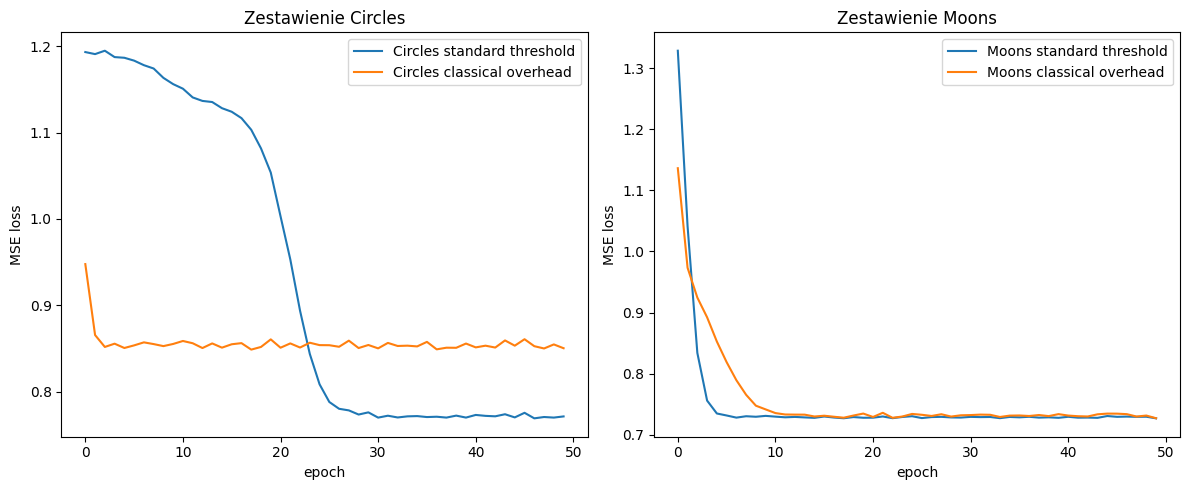

In [150]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

ax1.plot(hist_c["loss"], label="Circles standard threshold")
ax1.plot(hist_c_oh["loss"], label="Circles classical overhead")
ax1.set_xlabel("epoch")
ax1.set_ylabel("MSE loss")
ax1.set_title("Zestawienie Circles")
ax1.legend()

ax2.plot(hist_m["loss"], label="Moons standard threshold")
ax2.plot(hist_m_oh["loss"], label="Moons classical overhead")
ax2.set_xlabel("epoch")
ax2.set_ylabel("MSE loss")
ax2.set_title("Zestawienie Moons")
ax2.legend()

plt.tight_layout()
plt.show()

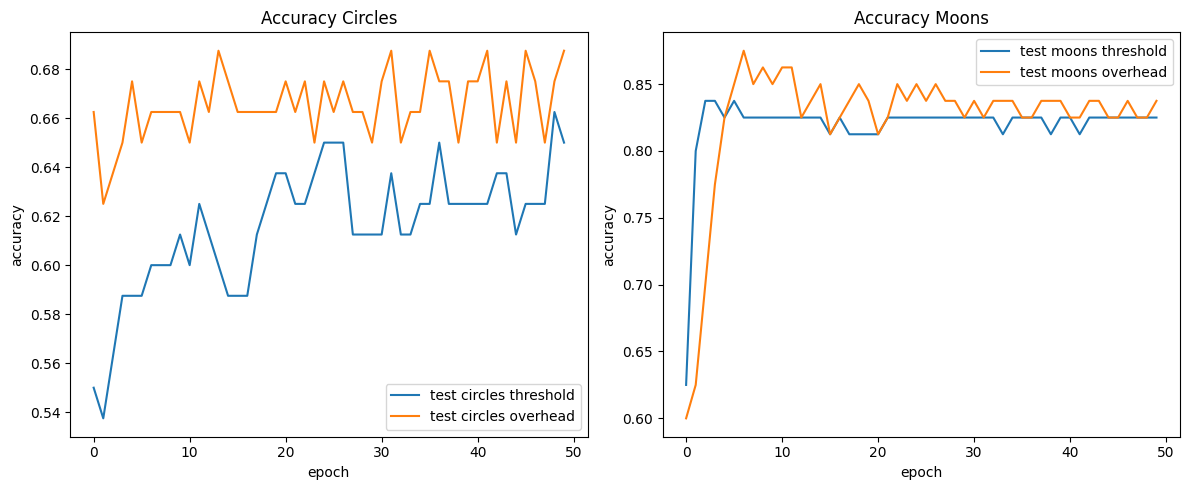

In [151]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

#ax1.plot(hist_c["train_acc"], label="train circles threshold")
ax1.plot(hist_c["test_acc"], label="test circles threshold")
#ax1.plot(hist_c_oh["train_acc"], label="train circles overhead")
ax1.plot(hist_c_oh["test_acc"], label="test circles overhead")
ax1.set_xlabel("epoch")
ax1.set_ylabel("accuracy")
ax1.set_title("Accuracy Circles")
ax1.legend()

#ax2.plot(hist_m["train_acc"], label="train moons threshold")
ax2.plot(hist_m["test_acc"], label="test moons threshold")
#ax2.plot(hist_m_oh["train_acc"], label="train moons overhead")
ax2.plot(hist_m_oh["test_acc"], label="test moons overhead")
ax2.set_xlabel("epoch")
ax2.set_ylabel("accuracy")
ax2.set_title("Accuracy Moons")
ax2.legend()

plt.tight_layout()
plt.show()

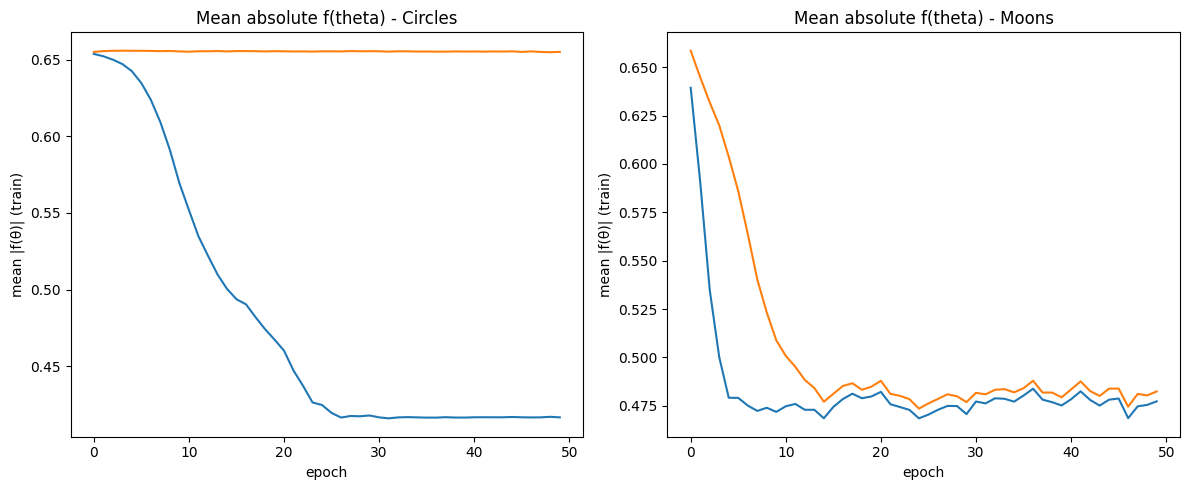

In [152]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

ax1.plot(hist_c["mean_abs_f_train"], label = "circles threshold")
ax1.plot(hist_c_oh["mean_abs_f_train"], label = "circles overhead")
ax1.set_xlabel("epoch")
ax1.set_ylabel("mean |f(θ)| (train)")
ax1.set_title("Mean absolute f(theta) - Circles")

ax2.plot(hist_m["mean_abs_f_train"], label = "moons threshold")
ax2.plot(hist_m_oh["mean_abs_f_train"], label = "moons overhead")
ax2.set_xlabel("epoch")
ax2.set_ylabel("mean |f(θ)| (train)")
ax2.set_title("Mean absolute f(theta) - Moons")

plt.tight_layout()
plt.show()

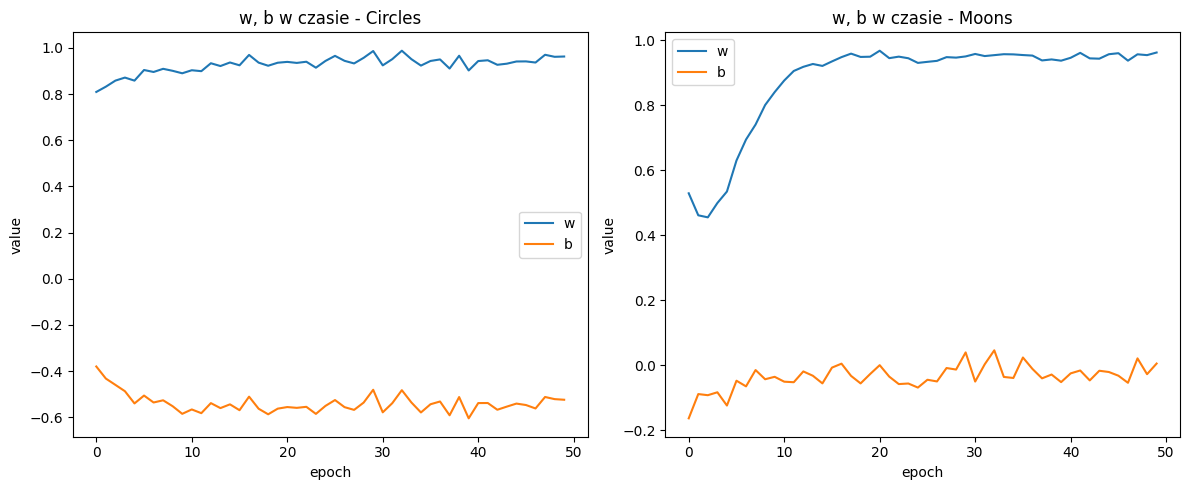

In [153]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

ax1.plot(hist_c_oh["w"], label="w")
ax1.plot(hist_c_oh["b"], label="b")
ax1.set_xlabel("epoch")
ax1.set_ylabel("value")
ax1.set_title("w, b w czasie - Circles")
ax1.legend()

ax2.plot(hist_m_oh["w"], label="w")
ax2.plot(hist_m_oh["b"], label="b")
ax2.set_xlabel("epoch")
ax2.set_ylabel("value")
ax2.set_title("w, b w czasie - Moons")
ax2.legend()

plt.tight_layout()
plt.show()